# 4_gunici — Gün İçi Tahmin: Yayın Gecikmesine Göre 3 Saat İleri

**Neden:** Gerçekleşen tüketim saatlik olarak **2 saat gecikmeyle** yayımlanıyor (EPDK 10711 sayılı kurul kararı, veri listesi: S+2). `3_model`'deki LSTM, bir saat önceki gerçek tüketimi kullanarak bir sonraki saati tahmin ediyordu (test MAPE %0,79). Ama canlıda t anında bilinen en son değer t−2. Bu durumda bir sonraki saat (t+1), bilinen son değerden **3 adım ileride**. Bu notebook modelleri bu gerçek koşula göre kuruyor.

- **A.** Kurulum, veri ve `3_model` ile aynı ayrım
- **B.** Özellikler ve kıyas ölçütleri
- **C.** XGBoost, 3 saat ileri
- **D.** LSTM, 3 saat ileri
- **E.** Karşılaştırma, hata analizi, belirsizlik bandı ve kayıt

**Girdiler:** `data/tr_ozellikli_saatlik.csv`, `metrics/tr_model_sonuclari.json` (`3_model`'in eğitim dönemi HDD/CDD bazları)

## A. Kurulum ve Veri

In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import xgboost as xgb

KOK = r"C:\Deep_Learning_to_AI_Agents\Bitirme_Proje_Bonus"
np.random.seed(42)

df = pd.read_csv(os.path.join(KOK, "data", "tr_ozellikli_saatlik.csv"))
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)
with open(os.path.join(KOK, "metrics", "tr_model_sonuclari.json"), encoding="utf-8") as f:
    m3 = json.load(f)
BH_TR, BC_TR = m3["hdd_tabani_egitim_c"], m3["cdd_tabani_egitim_c"]
df["hdd_tr"] = np.maximum(0, BH_TR - df["tavg_c"])
df["cdd_tr"] = np.maximum(0, df["tavg_c"] - BC_TR)

EGITIM_BIT = pd.Timestamp("2024-10-01T00:00:00+03:00")
DOGRULAMA_BIT = pd.Timestamp("2025-10-01T00:00:00+03:00")
TEST_BIT = pd.Timestamp("2026-09-23T00:00:00+03:00")
df["bolum"] = np.select([df["date"] < EGITIM_BIT, df["date"] < DOGRULAMA_BIT, df["date"] < TEST_BIT],
                        ["egitim", "dogrulama", "test"], default="disarida")
print(df.groupby("bolum")["date"].agg(["min", "max", "count"]).to_string())
print(f"HDD/CDD bazlari (3_model, egitim): {BH_TR} / {BC_TR} C")

                                min                       max  count
bolum                                                               
disarida  2026-09-23 00:00:00+03:00 2026-09-27 23:00:00+03:00    120
dogrulama 2024-10-01 00:00:00+03:00 2025-09-30 23:00:00+03:00   8760
egitim    2016-04-01 00:00:00+03:00 2024-09-30 23:00:00+03:00  74520
test      2025-10-01 00:00:00+03:00 2026-09-22 23:00:00+03:00   8568
HDD/CDD bazlari (3_model, egitim): 14.0 / 17.0 C


## B. Özellikler ve Kıyas Ölçütleri

**Zaman kurgusu:** Hedef saat t+1. Bilinen en son tüketim t−2. Yani hedef saate göre en kısa gecikme **3 saat** (`ADIM = 3`).

**XGBoost özellikleri:**
- Hedef saatin takvim, tatil ve sıcaklık özellikleri. Bunlar önceden biliniyor.
- Tüketim gecikmeleri: 3, 4, 5, 24 ve 168 saat.
- Bilinen son 24 saatin ortalaması (3 saat kaydırılmış).

**Kıyas ölçütleri:**
- **Son bilinen değer:** 3 saat önceki tüketim.
- **Dün aynı saat:** 24 saat önceki tüketim.
- **Geçen hafta aynı saat:** 168 saat önceki tüketim.

In [2]:
ADIM = 3   # 2 saat yayin gecikmesi + 1 saat ileri

TAKVIM = ["saat", "gun", "ay", "hafta_sonu", "tatil_saat", "idari_izin", "bayram_gun_no",
          "bayram_once_gun", "bayram_sonra_gun"]
SICAKLIK = ["tavg_c", "hdd_tr", "cdd_tr"]
for k in [3, 4, 5, 24, 168]:
    df[f"g_lag_{k}"] = df["consumption"].shift(k)
df["g_rol_24"] = df["consumption"].shift(ADIM).rolling(24).mean()
F_XGB = TAKVIM + SICAKLIK + ["g_lag_3", "g_lag_4", "g_lag_5", "g_lag_24", "g_lag_168", "g_rol_24"]
F_LSTM = ["consumption"] + TAKVIM + SICAKLIK

def metrik(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"RMSPE": float(np.sqrt(np.mean(((y - p) / y) ** 2))),
            "MAPE_%": float(np.mean(np.abs((y - p) / y)) * 100),
            "MAE_MWh": float(np.mean(np.abs(y - p)))}

def ayir(ozellik):
    d = df.dropna(subset=ozellik + ["consumption"])
    return {b: d[d["bolum"] == b] for b in ["egitim", "dogrulama", "test"]}
print("XGBoost:", len(F_XGB), "ozellik | LSTM:", len(F_LSTM), "ozellik")

XGBoost: 18 ozellik | LSTM: 13 ozellik


## C. XGBoost — 3 Saat İleri

`3_model` ile aynı parametreler; doğrulama dönemine göre erken durdurma.

In [3]:
XGB_PARAM = dict(n_estimators=2000, learning_rate=0.03, max_depth=8, min_child_weight=5, subsample=0.8,
                 colsample_bytree=0.8, reg_lambda=1.0, tree_method="hist", early_stopping_rounds=100,
                 eval_metric="rmse", random_state=42, n_jobs=-1)
s = ayir(F_XGB)
t0 = time.time()
m_xgb = xgb.XGBRegressor(**XGB_PARAM)
m_xgb.fit(s["egitim"][F_XGB], s["egitim"]["consumption"],
          eval_set=[(s["dogrulama"][F_XGB], s["dogrulama"]["consumption"])], verbose=False)
p_dog_xgb = m_xgb.predict(s["dogrulama"][F_XGB])
print(f"XGBoost 3 saat ileri: {time.time() - t0:.0f} sn | iterasyon {m_xgb.best_iteration} | dogrulama:",
      {k: round(v, 4) for k, v in metrik(s["dogrulama"]["consumption"], p_dog_xgb).items()})
m_xgb.save_model(os.path.join(KOK, "agent", "tr_xgb_3saat.json"))
onem = pd.Series(m_xgb.feature_importances_, index=F_XGB).sort_values(ascending=False)
print("\nOzellik onemi (ilk 8):"); print(onem.head(8).round(3).to_string())

XGBoost 3 saat ileri: 9 sn | iterasyon 1330 | dogrulama: {'RMSPE': 0.021, 'MAPE_%': 1.4616, 'MAE_MWh': 595.8134}

Ozellik onemi (ilk 8):
g_lag_168           0.331
g_lag_24            0.201
bayram_once_gun     0.149
tatil_saat          0.089
gun                 0.050
g_lag_3             0.048
bayram_sonra_gun    0.047
saat                0.022


## D. LSTM — 3 Saat İleri

`3_model`'deki mimari ve eğitim ayarları aynen korunuyor. Tek fark pencerenin konumu:
- Hedef j saati için pencere, bilinen son değerle, yani **j−3'te** bitiyor.
- Pencere 24 satır: j−26'dan j−3'e kadar.
- Ölçekleyiciler yalnızca eğitim verisiyle fit ediliyor.

Atlamak için `EGIT_LSTM = False` yapın.

Pencere sayisi | egitim: 74494 dogrulama: 8760 test: 8568
Kontrol: ilk test hedefi 2025-10-01 00:00:00+03:00 | pencerenin son satiri 2025-09-30 21:00:00+03:00 | fark 3 saat (beklenen 3)
Epoch 1/40
291/291 - 24s - 81ms/step - loss: 0.0472 - val_loss: 0.0348
Epoch 2/40
291/291 - 16s - 56ms/step - loss: 0.0255 - val_loss: 0.0264
Epoch 3/40
291/291 - 13s - 43ms/step - loss: 0.0207 - val_loss: 0.0215
Epoch 4/40
291/291 - 15s - 50ms/step - loss: 0.0182 - val_loss: 0.0195
Epoch 5/40
291/291 - 17s - 59ms/step - loss: 0.0175 - val_loss: 0.0197
Epoch 6/40
291/291 - 17s - 60ms/step - loss: 0.0165 - val_loss: 0.0178
Epoch 7/40
291/291 - 18s - 62ms/step - loss: 0.0159 - val_loss: 0.0189
Epoch 8/40
291/291 - 16s - 55ms/step - loss: 0.0154 - val_loss: 0.0189
Epoch 9/40
291/291 - 19s - 64ms/step - loss: 0.0148 - val_loss: 0.0180
Epoch 10/40
291/291 - 21s - 72ms/step - loss: 0.0146 - val_loss: 0.0180
Epoch 11/40
291/291 - 19s - 66ms/step - loss: 0.0142 - val_loss: 0.0175
Epoch 12/40
291/291 - 19s - 65m

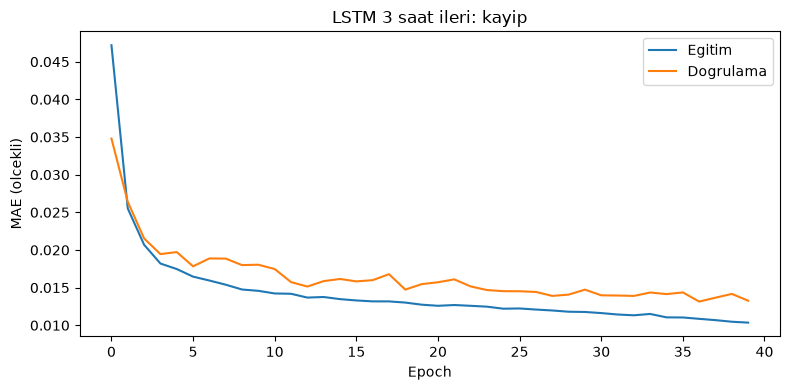

In [4]:
EGIT_LSTM = True
EPOCH = 40
PENCERE = 24

if EGIT_LSTM:
    import tensorflow as tf
    from numpy.lib.stride_tricks import sliding_window_view
    from sklearn.preprocessing import MinMaxScaler
    tf.keras.utils.set_random_seed(42)

    X_all = df[F_LSTM].values.astype("float32")
    y_all = df["consumption"].values.astype("float32")
    egm = (df["bolum"] == "egitim").values
    sx = MinMaxScaler().fit(X_all[egm])
    sy = MinMaxScaler().fit(y_all[egm].reshape(-1, 1))
    Xs = sx.transform(X_all).astype("float32")
    ys = sy.transform(y_all.reshape(-1, 1)).ravel().astype("float32")

    GERI = PENCERE + ADIM - 1                      # hedef j icin pencere baslangici j - GERI
    kotu = np.isnan(Xs).any(axis=1)
    cs = np.concatenate([[0], np.cumsum(kotu)])
    hedef = np.arange(GERI, len(df))
    bas = hedef - GERI
    gecerli = ((cs[bas + PENCERE] - cs[bas]) == 0) & ~np.isnan(ys[hedef])
    W = sliding_window_view(Xs, PENCERE, axis=0)    # W[i] = Xs[i : i + 24] (ozellik, 24)
    bolum_h = df["bolum"].values[hedef]

    def seq(b):
        idx = hedef[gecerli & (bolum_h == b)]
        return W[idx - GERI].transpose(0, 2, 1).copy(), ys[idx], idx

    Xtr, ytr, _ = seq("egitim")
    Xva, yva, iva = seq("dogrulama")
    Xte, yte, ite = seq("test")
    print("Pencere sayisi | egitim:", len(Xtr), "dogrulama:", len(Xva), "test:", len(Xte))
    son_satir = int(ite[0] - GERI + PENCERE - 1)
    print("Kontrol: ilk test hedefi", df["date"].iloc[ite[0]], "| pencerenin son satiri", df["date"].iloc[son_satir],
          f"| fark {int(ite[0] - son_satir)} saat (beklenen {ADIM})")

    lstm = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(PENCERE, len(F_LSTM))),
        tf.keras.layers.LSTM(64, return_sequences=True),
        tf.keras.layers.LSTM(32),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1),
    ])
    lstm.compile(optimizer="adam", loss="mae")
    t0 = time.time()
    gecmis = lstm.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCH, batch_size=256, verbose=2,
                      callbacks=[tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
    print(f"LSTM egitim suresi: {(time.time() - t0) / 60:.1f} dk | epoch: {len(gecmis.history['loss'])}")

    lstm_te = pd.Series(sy.inverse_transform(lstm.predict(Xte, verbose=0)).ravel(), index=pd.DatetimeIndex(df["date"].iloc[ite]))
    lstm_va = pd.Series(sy.inverse_transform(lstm.predict(Xva, verbose=0)).ravel(), index=pd.DatetimeIndex(df["date"].iloc[iva]))
    lstm.save(os.path.join(KOK, "agent", "tr_lstm_3saat.keras"))
    joblib.dump({"sx": sx, "sy": sy, "ozellikler": F_LSTM, "pencere": PENCERE, "adim": ADIM},
                os.path.join(KOK, "agent", "tr_lstm_3saat_olcekleyiciler.pkl"))

    plt.figure(figsize=(8, 4))
    plt.plot(gecmis.history["loss"], label="Egitim"); plt.plot(gecmis.history["val_loss"], label="Dogrulama")
    plt.xlabel("Epoch"); plt.ylabel("MAE (olcekli)"); plt.title("LSTM 3 saat ileri: kayip"); plt.legend()
    plt.tight_layout(); plt.savefig(os.path.join(KOK, "graphs", "tr_lstm_3saat_kayip.png"), dpi=150); plt.show()
else:
    lstm_te = lstm_va = None
    print("LSTM atlandi (EGIT_LSTM = False).")

## E. Karşılaştırma, Hata Analizi, Belirsizlik ve Kayıt

### E1. Ortak test kümesi ve model seçimi

Gün içi model (XGBoost veya LSTM), **doğrulama** döneminin MAPE'sine göre seçiliyor. Test sonuçları yalnızca raporlama için.

In [5]:
tst = s["test"].copy()
tahmin = pd.DataFrame({"date": tst["date"].reset_index(drop=True), "gercek": tst["consumption"].values})
tahmin["Naif: son bilinen deger (3 saat once)"] = tst["g_lag_3"].values
tahmin["Naif: dun ayni saat"] = tst["g_lag_24"].values
tahmin["Naif: gecen hafta ayni saat"] = tst["g_lag_168"].values
tahmin["XGBoost 3 saat ileri"] = m_xgb.predict(tst[F_XGB])
if lstm_te is not None:
    tahmin["LSTM 3 saat ileri"] = lstm_te.reindex(pd.DatetimeIndex(tst["date"])).values
tahmin = tahmin.dropna().reset_index(drop=True)
modeller = [c for c in tahmin.columns if c not in ["date", "gercek"]]
sonuc = {c: metrik(tahmin["gercek"], tahmin[c]) for c in modeller}
tablo = pd.DataFrame(sonuc).T.sort_values("MAPE_%")
print("Ortak test kumesi:", len(tahmin), "saat")
print(tablo.round(4).to_string())
print("\nKarsilastirma: 3_model 1 saat ileri (yayin gecikmesi yok): LSTM MAPE %0.79, XGBoost %0.96")

# Gun ici model secimi DOGRULAMA donemine gore (test secimde kullanilmaz)
dg = s["dogrulama"]
mape_dog = {"XGBoost 3 saat ileri": metrik(dg["consumption"], p_dog_xgb)["MAPE_%"]}
if lstm_va is not None:
    lv = lstm_va.reindex(pd.DatetimeIndex(dg["date"])).values
    ok = ~np.isnan(lv)
    mape_dog["LSTM 3 saat ileri"] = metrik(dg["consumption"].values[ok], lv[ok])["MAPE_%"]
en_iyi_model = min(mape_dog, key=mape_dog.get)
print("Dogrulama MAPE:", {k: round(v, 3) for k, v in mape_dog.items()}, "| SECILEN gun ici model:", en_iyi_model)

Ortak test kumesi: 8568 saat
                                        RMSPE  MAPE_%    MAE_MWh
LSTM 3 saat ileri                      0.0194  1.4711   600.2343
XGBoost 3 saat ileri                   0.0226  1.6153   673.2703
Naif: gecen hafta ayni saat            0.0854  4.9608  1935.8043
Naif: dun ayni saat                    0.0846  5.5886  2246.0193
Naif: son bilinen deger (3 saat once)  0.1077  8.4198  3370.1578

Karsilastirma: 3_model 1 saat ileri (yayin gecikmesi yok): LSTM MAPE %0.79, XGBoost %0.96
Dogrulama MAPE: {'XGBoost 3 saat ileri': 1.462, 'LSTM 3 saat ileri': 1.399} | SECILEN gun ici model: LSTM 3 saat ileri


### E2. Gün tipi ve saat

In [6]:
tt = tst.set_index("date").reindex(pd.DatetimeIndex(tahmin["date"]))
tahmin["gun_tipi"] = np.select(
    [(tt["bayram_once_gun"].values == 0) & (tt["bayram_sonra_gun"].values == 0), tt["tatil_tam"].values == 1,
     tt["idari_izin"].values == 1, tt["hafta_sonu"].values == 1],
    ["bayram (arife dahil)", "sabit tatil", "idari izin", "hafta sonu"], default="normal is gunu")
ape = pd.DataFrame({c: (tahmin["gercek"] - tahmin[c]).abs() / tahmin["gercek"] * 100 for c in modeller})
tip = ape.groupby(tahmin["gun_tipi"]).mean()
tip.insert(0, "saat_sayisi", tahmin["gun_tipi"].value_counts())
print("Gun tipine gore MAPE (%):"); print(tip.round(2).to_string())
saat = ape.groupby(tahmin["date"].dt.hour)[[en_iyi_model]].mean()
print(f"\nSaate gore MAPE (%), secilen model ({en_iyi_model}):"); print(saat.round(2).T.to_string())

Gun tipine gore MAPE (%):
                      saat_sayisi  Naif: son bilinen deger (3 saat once)  Naif: dun ayni saat  Naif: gecen hafta ayni saat  XGBoost 3 saat ileri  LSTM 3 saat ileri
gun_tipi                                                                                                                                                           
bayram (arife dahil)          216                                   8.43                 8.29                        33.34                  3.31               2.55
hafta sonu                   2352                                   7.88                 8.02                         4.14                  1.45               1.49
idari izin                     24                                   8.20                 2.79                        14.08                  3.62               1.50
normal is gunu               5808                                   8.65                 4.40                         4.04                  1.58          

### E3. Belirsizlik bandı (doğrulama döneminden)

Agent'ın temkinli marj kontrolü için. Her saat için eksik tahmin oranının %90'lık üst dilimi (q90) hesaplanıyor:

u = (gerçek − tahmin) / tahmin

Temkinli tahmin = tahmin × (1 + q90). Test dönemi bu hesaba girmiyor. Bandın test döneminde gerçekleşen tüketimi ne sıklıkla kapsadığı ayrıca raporlanıyor; hedef yaklaşık %90.

In [7]:
if en_iyi_model.startswith("LSTM"):
    p_dog = lstm_va.reindex(pd.DatetimeIndex(dg["date"])).values
else:
    p_dog = p_dog_xgb
u = pd.Series((dg["consumption"].values - p_dog) / p_dog, index=dg["date"].dt.hour.values).dropna()
q90 = u.groupby(level=0).quantile(0.90)
print("Secilen gun ici model (dogrulamaya gore):", en_iyi_model)
print("Saatlik q90 (eksik tahmin orani, %):"); print((q90 * 100).round(2).to_frame("q90_%").T.to_string())

ust = tahmin[en_iyi_model] * (1 + q90.reindex(tahmin["date"].dt.hour.values).values)
kapsama = float((tahmin["gercek"] <= ust).mean() * 100)
print(f"\nTest doneminde gercek tuketimin temkinli tahminin altinda kalma orani: %{kapsama:.1f} (hedef ~%90)")

Secilen gun ici model (dogrulamaya gore): LSTM 3 saat ileri
Saatlik q90 (eksik tahmin orani, %):
         0    1     2     3     4     5     6     7    8     9     10    11    12    13    14    15    16    17    18    19    20    21    22    23
q90_%  0.64  0.6  0.93  0.98  1.54  2.06  2.04  1.92  2.3  1.46  1.55  2.57  2.11  2.32  1.87  2.04  2.54  3.49  3.44  3.47  3.66  2.73  1.96  1.45

Test doneminde gercek tuketimin temkinli tahminin altinda kalma orani: %87.6 (hedef ~%90)


### E4. Örnek hafta ve kayıt

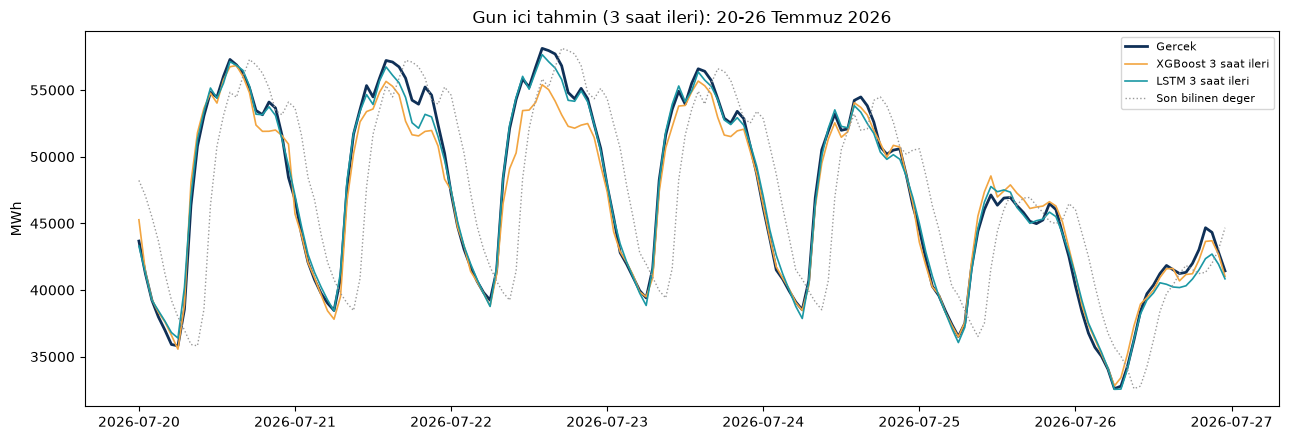

Kaydedildi | en iyi gun ici model: LSTM 3 saat ileri


In [8]:
p = tahmin[(tahmin["date"] >= pd.Timestamp("2026-07-20T00:00:00+03:00")) & (tahmin["date"] < pd.Timestamp("2026-07-27T00:00:00+03:00"))]
plt.figure(figsize=(13, 4.5))
plt.plot(p["date"], p["gercek"], color="#0F3057", linewidth=2, label="Gercek")
for c, renk in [("XGBoost 3 saat ileri", "#F2A541"), ("LSTM 3 saat ileri", "#1B98A4")]:
    if c in p:
        plt.plot(p["date"], p[c], color=renk, linewidth=1.2, label=c)
plt.plot(p["date"], p["Naif: son bilinen deger (3 saat once)"], color="#999999", linewidth=1, linestyle=":", label="Son bilinen deger")
plt.title("Gun ici tahmin (3 saat ileri): 20-26 Temmuz 2026"); plt.ylabel("MWh"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(KOK, "graphs", "tr_gunici_ornek_hafta.png"), dpi=150); plt.show()

with open(os.path.join(KOK, "metrics", "tr_gunici_sonuclari.json"), "w", encoding="utf-8") as f:
    json.dump({"adim_saat": ADIM, "test_saat": int(len(tahmin)), "sonuclar": sonuc, "en_iyi_model": en_iyi_model,
               "q90_saatlik": {int(k): round(float(v), 5) for k, v in q90.items()},
               "q90_kapsama_test_%": round(kapsama, 2)}, f, ensure_ascii=False, indent=2)
tahmin[["date", "gercek", "gun_tipi"] + modeller].to_csv(os.path.join(KOK, "metrics", "tr_gunici_test_tahminleri.csv"), index=False)
print("Kaydedildi | en iyi gun ici model:", en_iyi_model)